# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Aurea McIntosh, Evie McMahan, Zoe Edelblum

**Date:** 11/16/2026

# Question 1: Check out the data set `heart_failure` and appropriately clean it.

In [91]:
import pandas as pd

# check the dataset
df = pd.read_csv('data/heart_failure/heart_failure_clinical_records_dataset.csv')

print("Shape before cleaning:", df.shape)
df.info() # dtypes + non-null counts
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Shape before cleaning: (299, 13)
<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5

Upon first inspection, there are 0 missing values and 0 duplicate rows in the heart_failure dataset, which has 299 columns and 13 rows. All datatypes are integers except for age, platelets, and serum_creatinine, which are floats. These are continuous numerical variables, so float data types are practical, but I will look into the age variable more.

In [2]:
print("Non-whole number age:\n", df[df['age'] != df['age'].round()]['age'])
print("\nSummary stats:\n", df.describe().T[['min', 'mean', 'max']])
print("\nTarget variable:\n", df['DEATH_EVENT'].value_counts(normalize=True))
df.head()

Non-whole number age:
 185    60.667
188    60.667
Name: age, dtype: float64

Summary stats:
                               min           mean       max
age                          40.0      60.833893      95.0
anaemia                       0.0       0.431438       1.0
creatinine_phosphokinase     23.0     581.839465    7861.0
diabetes                      0.0       0.418060       1.0
ejection_fraction            14.0      38.083612      80.0
high_blood_pressure           0.0       0.351171       1.0
platelets                 25100.0  263358.029264  850000.0
serum_creatinine              0.5       1.393880       9.4
serum_sodium                113.0     136.625418     148.0
sex                           0.0       0.648829       1.0
smoking                       0.0       0.321070       1.0
time                          4.0     130.260870     285.0
DEATH_EVENT                   0.0       0.321070       1.0

Target variable:
 DEATH_EVENT
0    0.67893
1    0.32107
Name: proportion, dtype

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [93]:
# clean the dataset
df_clean = df.copy()

# fix fractional ages (two rows have 60.667) by rounding to whole integers
df_clean['age'] = df_clean['age'].round().astype(int)

print("Shape after cleaning:", df_clean.shape)

Shape after cleaning: (299, 13)


The heart_failure dataset was inspected (299 rows, 13 columns) for missing values, duplicate rows, invalid ranges, and data types. There are 0 missing values and 0 duplicate rows, so no rows need to be dropped. All clinical measurements fall within realistic ranges, demonstrated by no negative values or values that couldn't appear in a lab result. For example, platelet lab counts reach be 850,000 platelets, although that is significantly elevated. We checked this by Googling lab values. The outcome, DEATH_EVENT, is binary with no missing values, and it showed that approximately 32% of patients ended up dying (value = 1). All data types are integers except age, platelets, and serum_creatinine, which are floats. These are continuous variables, so floats are appropriate. However, age has only two rows that aren’t whole numbers (both 60.667), while every other age is a whole number. I rounded age to whole integers (int) to be consistent. All columns are numeric, so no categorical encoding is needed.

# Question 2: Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.

Decision Tree Train accuracy: 0.9163
Logistic Regression Train accuracy: 0.8661

Decision Tree Test Accuracy: 0.6833
Decision Tree Confusion Matrix:
 [[28  7]
 [12 13]]

Logistic Regression Test Accuracy: 0.8000
Logistic Regression Confusion Matrix:
 [[34  1]
 [11 14]]

Baseline accuracy:
 DEATH_EVENT
0    0.583333
1    0.416667
Name: proportion, dtype: float64


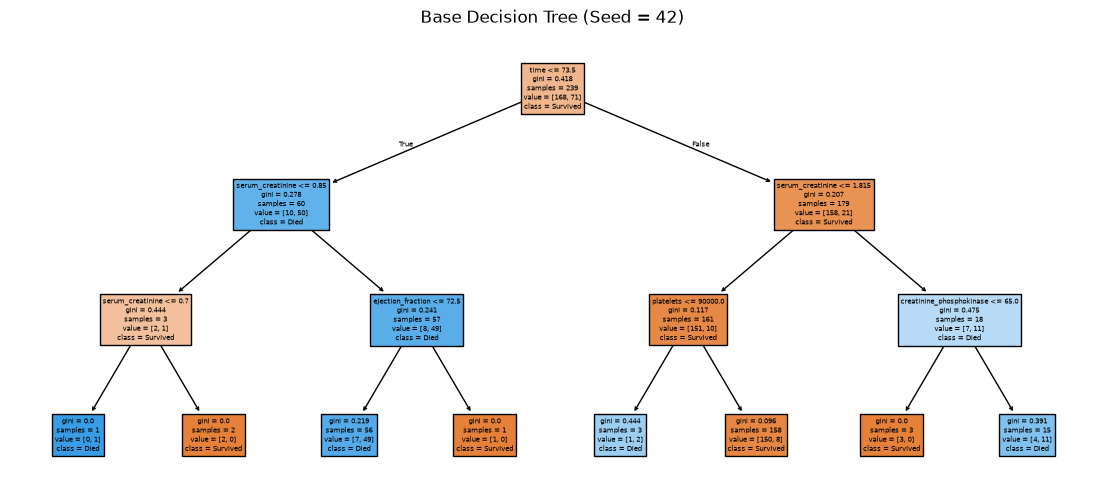


Base Logistic Regression Coefficients:
age                         0.6617
anaemia                    -0.0517
creatinine_phosphokinase    0.1106
diabetes                    0.1641
ejection_fraction          -0.8763
high_blood_pressure        -0.0608
platelets                  -0.1704
serum_creatinine            0.7019
serum_sodium               -0.2605
sex                        -0.3627
smoking                     0.0714
time                       -1.6522
dtype: float64


In [94]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import pandas as pd

# separate features (X) and target (y)
X = df_clean.drop('DEATH_EVENT', axis=1)
y = df_clean['DEATH_EVENT']

# performed train test split for a specific seed (save the seed for reproducibility)
seed_base = 42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=seed_base
)

# scale features so logistic regression is clean
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# fit a tree and a linear (logistic) model on the training data
tree_base = DecisionTreeClassifier(max_depth=3, random_state=seed_base)
tree_base.fit(X_train, y_train)

log_base = LogisticRegression(max_iter=1000)
log_base.fit(X_train_scaled, y_train)

# evaluated performance on the test data
tree_test_classes = tree_base.predict(X_test)
log_test_classes = log_base.predict(X_test_scaled)

print(f"Decision Tree Train accuracy: {accuracy_score(y_train, tree_base.predict(X_train)):.4f}")
print(f"Logistic Regression Train accuracy: {accuracy_score(y_train, log_base.predict(X_train_scaled)):.4f}")

print(f"\nDecision Tree Test Accuracy: {accuracy_score(y_test, tree_test_classes):.4f}")
print("Decision Tree Confusion Matrix:\n", confusion_matrix(y_test, tree_test_classes))

print(f"\nLogistic Regression Test Accuracy: {accuracy_score(y_test, log_test_classes):.4f}")
print("Logistic Regression Confusion Matrix:\n", confusion_matrix(y_test, log_test_classes))
print("\nBaseline accuracy:\n", y_test.value_counts(normalize=True))

# set aside the predictions the models make
pred_tree_base = tree_base.predict_proba(X_test)[:, 1]
pred_log_base = log_base.predict_proba(X_test_scaled)[:, 1]

# inspect the base tree and logistic coefficients
plt.figure(figsize=(14, 6))
plot_tree(tree_base, feature_names=X.columns, class_names=['Survived', 'Died'], filled=True)
plt.title(f"Base Decision Tree (Seed = {seed_base})")
plt.show()

print("\nBase Logistic Regression Coefficients:")
print(pd.Series(log_base.coef_[0], index=X.columns).round(4))

After splitting the data 80/20 using a seed of 42, we fit a decision tree and logistic regression model on our training data. We used a logistic regression rather than linear regression because our target variable of DEATH_EVENT is binary (and a linear model could predict a result below 0 or above 1). On the test data, the logistic regression was more accurate than the decision tree, at 80% versus 68.3%. For this specific seed, the baseline of always predicting survival (when DEATH_EVENT = 0) was 58.3%, so both models did perform better than the baseline.

Looking at the confusion matrices, we can see that the decision tree correctly predicted death 13 out of 25 times and produced 7 false positives, predicting death for 7 patients who actually survived. In comparison, the logistic regression correctly predicted 14 out of 25 deaths and only predicted 1 false positive. Overall, although both models only identified death approximately half the time, the logistic regression did a much better job at not falsely predicting death.

The decision tree had a much larger accuracy divergence between training and testing datasets (91.6% vs. 68.3%), which suggests overfitting since the predictions didn't apply as well on the new data. The logistic regression was more consistent across training and testing datasets.

# Question 3: Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients? Set aside the predictions these models make.

In [95]:
# Seed 1
seed_1 = 1
X_train_1, X_test_1, y_train_1, y_test_1 = train_test_split(X, y, test_size=0.2, random_state=seed_1)
scaler_1 = StandardScaler()
X_train_1_sc = scaler_1.fit_transform(X_train_1)

tree_1 = DecisionTreeClassifier(max_depth=3, random_state=seed_1)
tree_1.fit(X_train_1, y_train_1)

log_1 = LogisticRegression(max_iter=1000)
log_1.fit(X_train_1_sc, y_train_1)

# Set aside predictions on the base test set (X_test)
pred_tree_1 = tree_1.predict_proba(X_test)[:, 1]
pred_log_1 = log_1.predict_proba(scaler_1.transform(X_test))[:, 1]

# Seed 10
seed_10 = 10
X_train_10, X_test_10, y_train_10, y_test_10 = train_test_split(X, y, test_size=0.2, random_state=seed_10)
scaler_10 = StandardScaler()
X_train_10_sc = scaler_10.fit_transform(X_train_10)

tree_10 = DecisionTreeClassifier(max_depth=3, random_state=seed_10)
tree_10.fit(X_train_10, y_train_10)

log_10 = LogisticRegression(max_iter=1000)
log_10.fit(X_train_10_sc, y_train_10)

# Set aside predictions on the base test set (X_test)
pred_tree_10 = tree_10.predict_proba(X_test)[:, 1]
pred_log_10 = log_10.predict_proba(scaler_10.transform(X_test))[:, 1]

# Seed 99
seed_99 = 99
X_train_99, X_test_99, y_train_99, y_test_99 = train_test_split(X, y, test_size=0.2, random_state=seed_99)
scaler_99 = StandardScaler()
X_train_99_sc = scaler_99.fit_transform(X_train_99)

tree_99 = DecisionTreeClassifier(max_depth=3, random_state=seed_99)
tree_99.fit(X_train_99, y_train_99)

log_99 = LogisticRegression(max_iter=1000)
log_99.fit(X_train_99_sc, y_train_99)

# Set aside predictions on the base test set (X_test)
pred_tree_99 = tree_99.predict_proba(X_test)[:, 1]
pred_log_99 = log_99.predict_proba(scaler_99.transform(X_test))[:, 1]

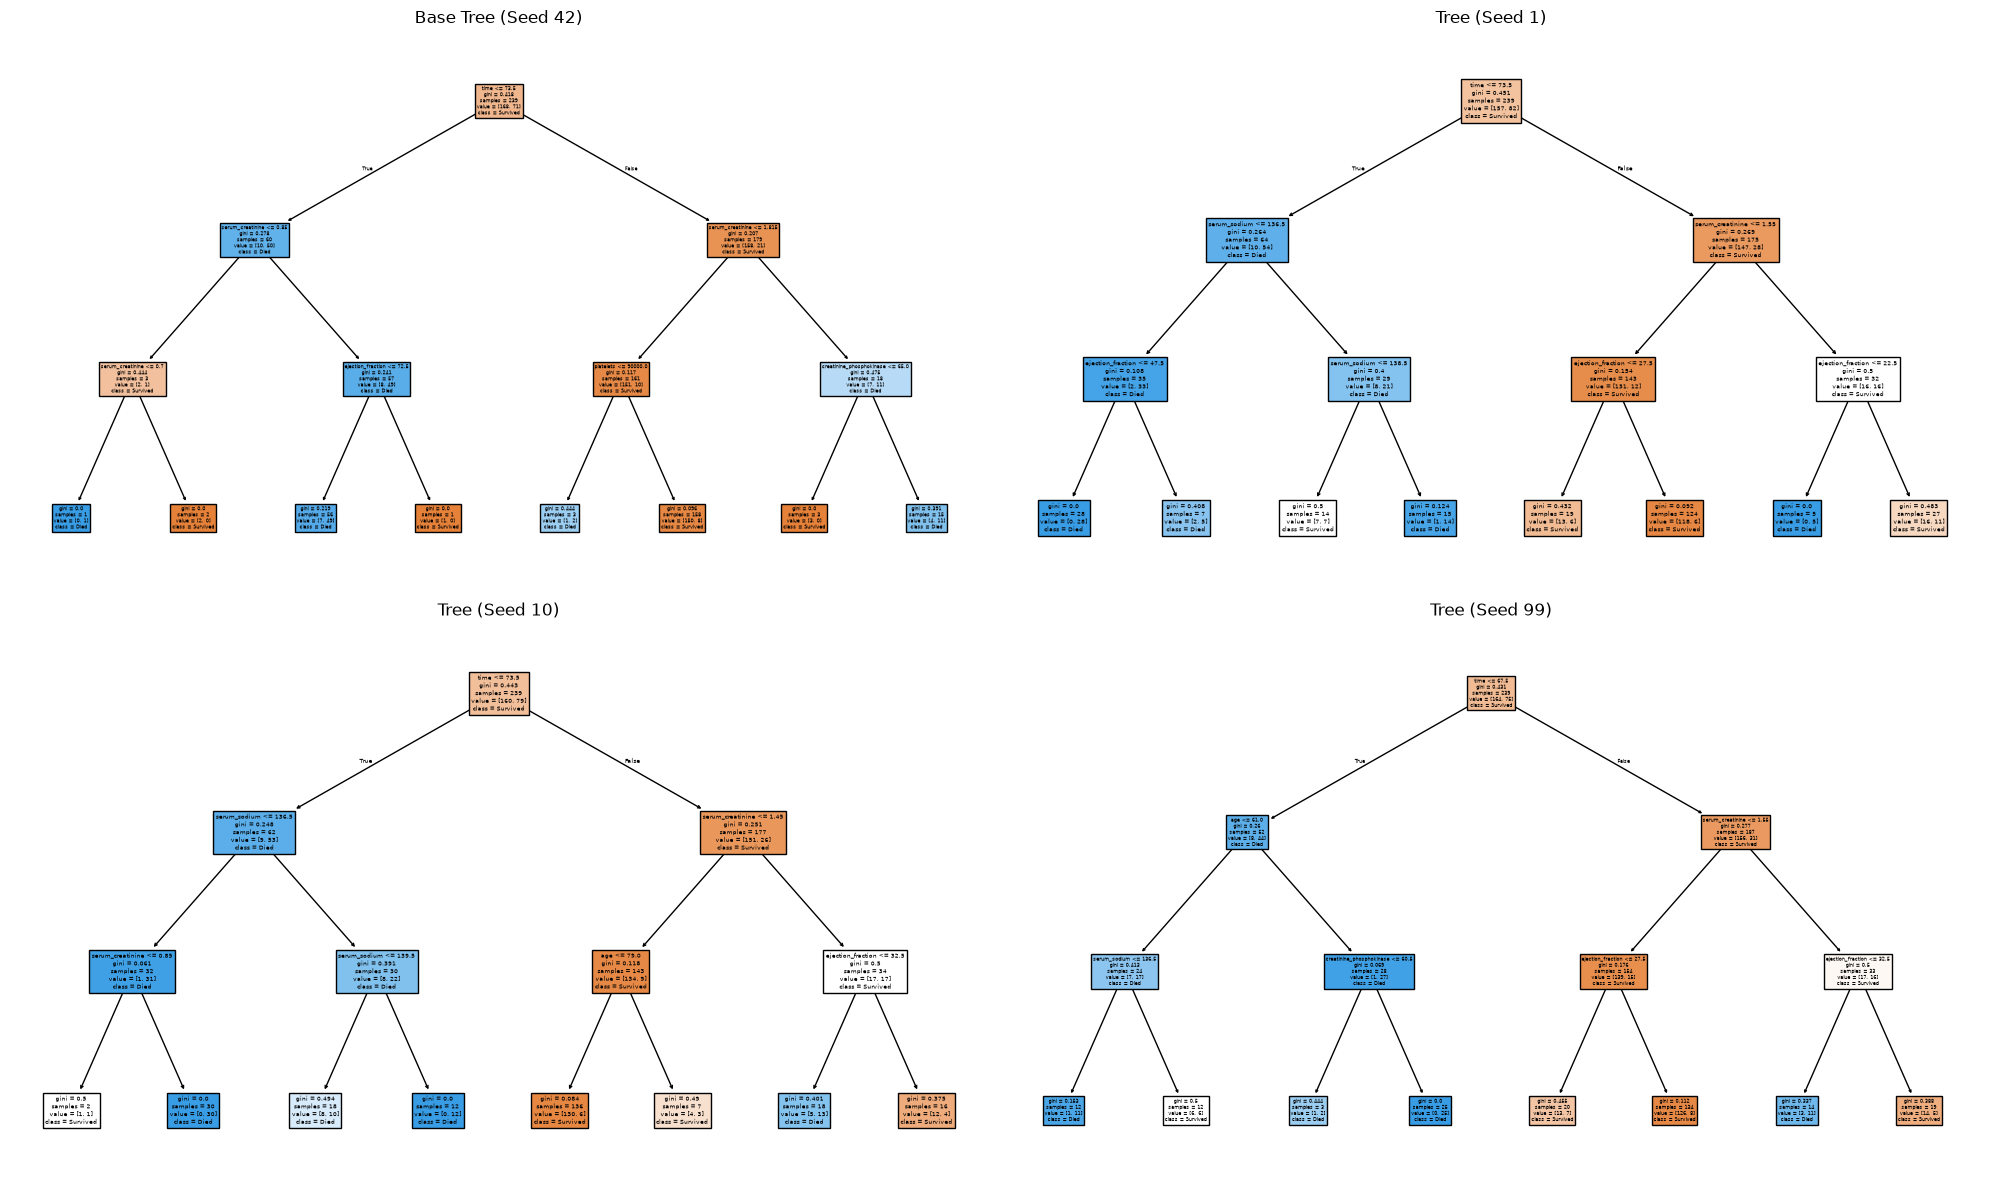

Logistic Regression Coefficients Across Seeds:
                          Base (42)  Seed 1  Seed 10  Seed 99
age                          0.6617  0.4269   0.5817   0.5564
anaemia                     -0.0517 -0.0292   0.1533  -0.0983
creatinine_phosphokinase     0.1106  0.2224   0.2050   0.1592
diabetes                     0.1641  0.1789   0.1621   0.0664
ejection_fraction           -0.8763 -0.7915  -0.9757  -0.9018
high_blood_pressure         -0.0608 -0.1224  -0.0709   0.0369
platelets                   -0.1704 -0.2394  -0.1799  -0.1948
serum_creatinine             0.7019  0.7312   1.1086   0.7202
serum_sodium                -0.2605 -0.2819  -0.2972  -0.2704
sex                         -0.3627 -0.1796  -0.1755  -0.2159
smoking                      0.0714 -0.0431  -0.0657   0.0664
time                        -1.6522 -1.4788  -1.6339  -1.3374


In [96]:
# Plot all 4 trees in a 2x2 grid so it can be compared
fig, axes = plt.subplots(2, 2, figsize=(20, 12))

plot_tree(tree_base, feature_names=X.columns, class_names=['Survived', 'Died'], filled=True, ax=axes[0, 0])
axes[0, 0].set_title("Base Tree (Seed 42)")

plot_tree(tree_1, feature_names=X.columns, class_names=['Survived', 'Died'], filled=True, ax=axes[0, 1])
axes[0, 1].set_title("Tree (Seed 1)")

plot_tree(tree_10, feature_names=X.columns, class_names=['Survived', 'Died'], filled=True, ax=axes[1, 0])
axes[1, 0].set_title("Tree (Seed 10)")

plot_tree(tree_99, feature_names=X.columns, class_names=['Survived', 'Died'], filled=True, ax=axes[1, 1])
axes[1, 1].set_title("Tree (Seed 99)")

plt.tight_layout()
plt.show()

# Compare Logistic Regression coefficients side by side
coef_table = pd.DataFrame({
    'Base (42)': log_base.coef_[0],
    'Seed 1': log_1.coef_[0],
    'Seed 10': log_10.coef_[0],
    'Seed 99': log_99.coef_[0]
}, index=X.columns)

print("Logistic Regression Coefficients Across Seeds:")
print(coef_table.round(4))

In [97]:
# Base (Seed 42)
tree_acc_base = accuracy_score(y_test, tree_base.predict(X_test))
log_acc_base = accuracy_score(y_test, log_base.predict(scaler.transform(X_test)))

# Seed 1
tree_acc_1 = accuracy_score(y_test_1, tree_1.predict(X_test_1))
log_acc_1 = accuracy_score(y_test_1, log_1.predict(scaler_1.transform(X_test_1)))

# Seed 10
tree_acc_10 = accuracy_score(y_test_10, tree_10.predict(X_test_10))
log_acc_10 = accuracy_score(y_test_10, log_10.predict(scaler_10.transform(X_test_10)))

# Seed 99
tree_acc_99 = accuracy_score(y_test_99, tree_99.predict(X_test_99))
log_acc_99 = accuracy_score(y_test_99, log_99.predict(scaler_99.transform(X_test_99)))

accuracy = pd.DataFrame({
    'Decision Tree': [tree_acc_base, tree_acc_1, tree_acc_10, tree_acc_99],
    'Logistic Regression': [log_acc_base, log_acc_1, log_acc_10, log_acc_99]
}, index=['Base (42)', 'Seed 1', 'Seed 10', 'Seed 99'])

print("Test Accuracy Across Seeds:")
print(accuracy.round(4))

Test Accuracy Across Seeds:
           Decision Tree  Logistic Regression
Base (42)         0.6833               0.8000
Seed 1            0.8667               0.8833
Seed 10           0.7833               0.7167
Seed 99           0.7500               0.8667


**How Different are the Decision Trees?**

Across the different random train-test splits, the decision trees change quite a bit, especially once you look past the very top split. All four trees start by splitting on time at the top, though even that cutoff changes slightly and stays at time <= 73.50 for seeds 42, 1, and 10, and dropping to time <= 67.50 for seed 99. Once you go down to the second and third levels, the trees differ more and more. For example, on the left side (time <= 73.50), the base tree (seed=42) splits on serum_creatinine and ejection_fraction, while seeds 1 and 10 both switch to serum_sodium, and seed 99 switches to age. The same thing happens on the right side (time > 73.50), where the bottom splits bounce between platelets, creatinine_phosphokinase, ejection_fraction, and age depending on the seed. Because a decision tree bulds branches one step at a time, changing a small portion of the training data can change what split appears to be the best, which then changes all the branches underneath. These differences also impact the test performance of the decision trees, as accuracy ranges from 86.7% to 68.3% across the different seeds.

**How Different Are the Linear Model Coefficients?**

While the decision tree models are inconsistent on each of the four random splits, the coefficients of the logistic regression model remain are more stable. The coefficients of the most influential features always have the exact same signs and nearly identical values in each split: time has coefficients between -1.34 and -1.65, ejection_fraction has coefficients between -0.79 and -0.98, serum_creatinine has coefficients between 0.70 and 1.11, age has coefficients between 0.43 and 0.66, and serum_sodium has coefficients between -0.26 and -0.30. Only the coefficients of binary features with small values such as anaemia, high_blood_pressure, and smoking change their signs in different splits. Unlike the decision tree model, the logistic regression model uses all the training samples for fitting the final curve at once, so a different sample doesn't have as large an impact on the coefficients. The testing accuracy did still vary between different seeds, however, ranging from 88.3% to 71.7%, which is a similar spread to the decision tree.

# Question 4: Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. But are they? Instead of focusing on the tree or model coefficients, do three things:

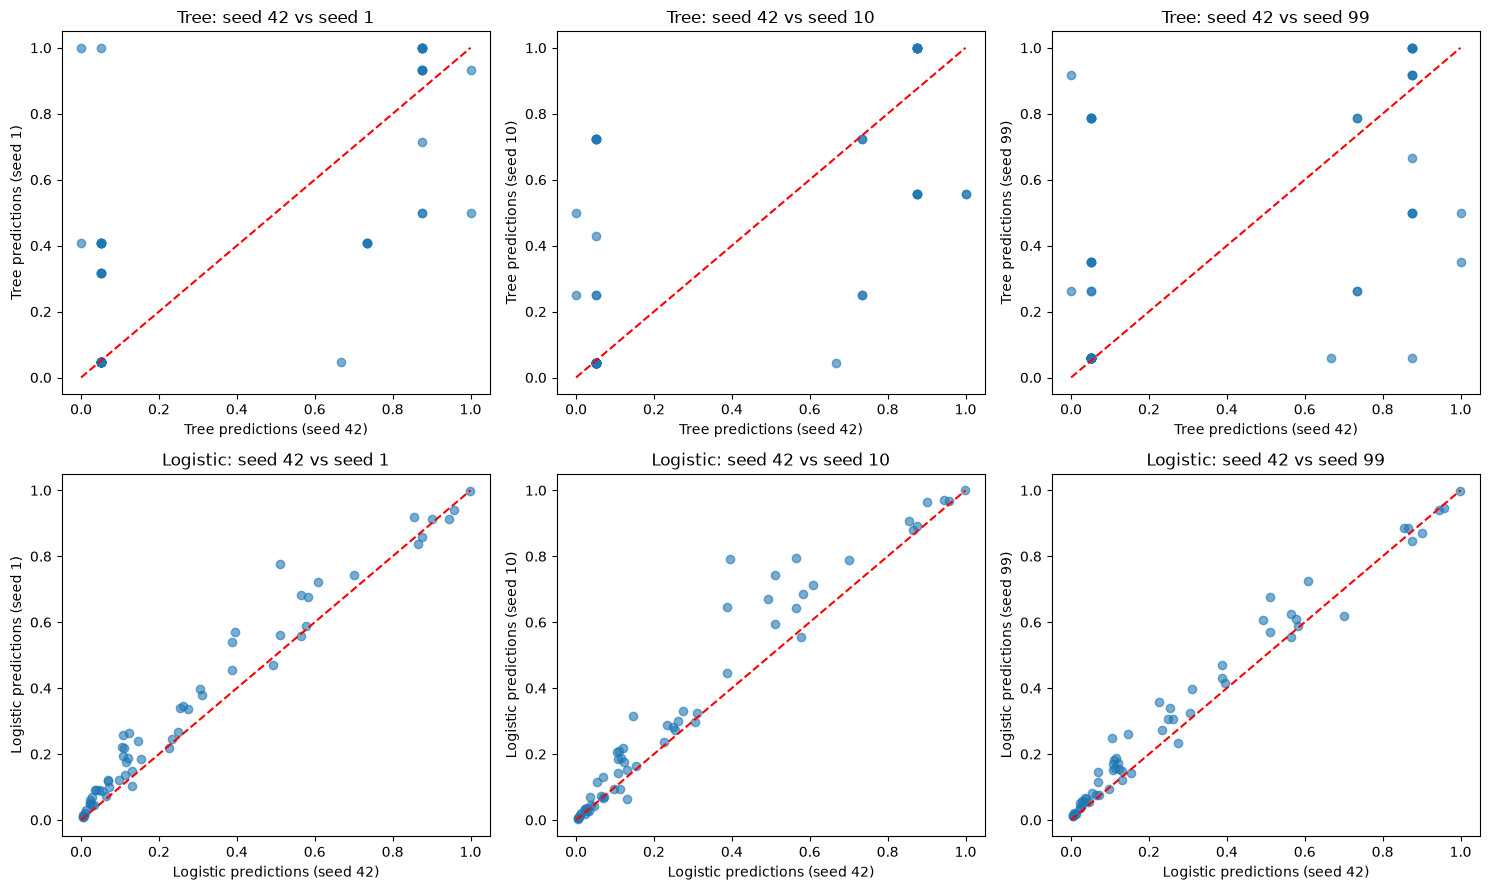

      Model  Seed  Correlation  Intercept  Slope    R^2
0      Tree     1        0.733      0.147  0.697  0.538
1      Tree    10        0.730      0.128  0.700  0.533
2      Tree    99        0.589      0.189  0.543  0.347
3  Logistic     1        0.982      0.052  0.986  0.965
4  Logistic    10        0.972      0.033  1.061  0.945
5  Logistic    99        0.988      0.040  0.978  0.976


In [98]:
from scipy import stats

seed_list = [1, 10, 99]
base = {'Tree': pred_tree_base, 'Logistic': pred_log_base}
alts = {
    'Tree':     {1: pred_tree_1, 10: pred_tree_10, 99: pred_tree_99},
    'Logistic': {1: pred_log_1,  10: pred_log_10,  99: pred_log_99},
}

#Base predictions versus alternative predictions
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, k in enumerate(['Tree', 'Logistic']):
    for j, s in enumerate(seed_list):
        ax = axes[i, j]
        ax.scatter(base[k], alts[k][s], alpha=0.6)
        ax.plot([0, 1], [0, 1], 'r--')
        ax.set_xlabel(f'{k} predictions (seed 42)')
        ax.set_ylabel(f'{k} predictions (seed {s})')
        ax.set_title(f'{k}: seed 42 vs seed {s}')

plt.tight_layout()
plt.show()

#Correlation and simple linear regression
rows = []

for k in ['Tree', 'Logistic']:
    for s in seed_list:
        res = stats.linregress(base[k], alts[k][s])
        rows.append({
            'Model': k,
            'Seed': s,
            'Correlation': res.rvalue,
            'Intercept': res.intercept,
            'Slope': res.slope,
            'R^2': res.rvalue ** 2,
        })

q4_table = pd.DataFrame(rows)
print(q4_table.round(3))

As we wrote about in Q3, the logistic regression coefficients do vary by different amounts across different seeds. For example, serum_sodium flucutates slightly from -0.26 to -0.30, serum_creatinine changes from 0.70 to 1.11, a few features flip signs, including anaemia and smoking flip. Even with these coefficient changes, the predictions the logistic models make are very similar to base seed model no matter the seed. This is proven through their correlations of 0.97 to 0.99, which means that the coefficient changes are not as substantial as they first appear.

**a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?**

For the logistic regression, the points fall close to the red y = x line in all three plots, which means the logistic predictions from the alternative seeds are very similar to the seed-42 logistic predictions. They sit slightly above the line in the middle range, most visibly for seed 10. For the trees, the points are scattered and show stripes as the tree can only output a few distinct probabilities. Many points are far from the line. For example, some observations the seed-42 tree scores near 0.0 get much higher values from the alternative tree. The tree predictions don't look reasonably similar, but the logistic predictions do.

**b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?**

The logistic regression predictions are all very highly correlated with the seed-42 model (0.97 to 0.99) with seed-99 being the most correlated to seeed-42. The tree predictions are much less correlated (0.59 to 0.73), with seed 99 the lowest. The logistic models agree on which observations are higher or lower risk, while the trees only moderately agree.

**c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?**

For the logistic regression, the intercepts are close to 0 (0.03 to 0.05), the slopes are close to 1 (0.98 to 1.06), and $R^2$ is high (0.95 to 0.98). This illustrates that the alternative models give nearly the same predictions as the seed-42 model. For the trees, the intercepts are not close to 0 (0.13 to 0.19), the slopes are well below 1 (0.54 to 0.70), and $R^2$ is low (0.35 to 0.54). The alternative trees do not reproduce the seed-42 predictions, and their predictions are compressed toward the middle.

# Question 5: Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?

Linear (logistic) models appear to have similar coefficients and predictions across the train and testing splits. For each seed, the coefficients come from the training data, and they vary slightly across different seeds. The larger absolute coefficients, which have the most impact on the prediction, such as time (-1.34 to -1.65), ejection_fraction (-0.79 to -0.98), and serum_creatinine (0.70 to 1.11), keep their same sign across all seeds. Smaller absolute value coefficients, which have less impact on the prediction, such as anaemia and smoking, do flip signs. It was also notable that when each seed’s model predicted on the same seed-42 test set, the correlations range from 0.97 to 0.99, the slopes were all close to one (0.98 to 1.06), the intercepts were close to zero (0.03 to 0.05), and the R² values were close to one (0.95 to 0.98) compared to the seed-42 model. This helps prove that the predictions don’t change a lot across different seeds.

Tree decision models are much less similar across train and testing splits. Although all four trees made their first split based on time, the cutoffs were different and the splits below changed based on the seed. For example, serum_sodium, age, and platelets are decision nodes in some trees, but they don't appear in others. The trees also generally predicted much accurately on their training data versus their test data, as discussed in Q2. Predictions are also not very similar because each tree node picks its split based on the best choice at that step without considering future splits, so small differences across training samples can make large changes to the structure of the tree. Our data supports this through correlations ranging from 0.59 to 0.73, slopes that are below 1 (from 0.54 to 0.70), and r2 values of 0.35 to 0.54 when each seed's tree predicts on the same base testing dataset.

# Question 6: True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

Based on our dataset, this statement is true for logistic regression, but it is false for decision trees. For logistic regression, the coefficients did appear to be different across seeds at first glance, and some even flipped signs, but the predictions were very similar when they all tested on the base seed's testing data set, as we have discussed at length in prior answers. This shows that even though they had a different appearance, they generated similar predictions. For decision trees, the models looked different with different splits across the different seeds, and their predictions also varied when tested on the same dataset. 

Because a decision tree picks each split greedily, small changes to the training data can make larger changes to the apperance, which has an impact on the predictions. On the other hand, logistic regressions fits the coefficients on the model at one time, so changes in the training sample only shift the predictions slightly. As a result, the type of model changes whether predictions are similar or different even if models have different appearances.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** af39b4c4a0c96f41682d10f553cbea76508d434a
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. Give me a concise numbered list of your proposed changes and revisions.

### *AI-proposed changes


**Correctness fixes**

1. **Q1 markdown: swapped dimensions.** The text says the dataset "has 299 columns and 13 rows." It's 299 rows and 13 columns (the code output confirms this).
2. **Q4 text: "seed 99 being the most correlated" is wrong.** The correlation table shows seed 99 is the *lowest* for trees (0.589) but the *highest* for logistic (0.988). Specify which model you mean.
3. **Q3/Q5 coefficient ranges.** Re-check the stated ranges against the table. Age is 0.43 to 0.66, ejection_fraction is -0.79 to -0.98, and serum_creatinine is 0.70 to 1.11, which are fine. But "time" in Q3 is -1.34 to -1.65 (correct), so keep these but add the base-seed column explicitly so readers can verify.
4. **Q2 interpretation of overfitting.** The statement "91.6% vs 68.3%" is right, but the test set only has 60 observations, so a single split's accuracy gap is noisy. Add a caveat, since Q3 shows tree test accuracy ranging from 68% to 87%.

**Methodological improvements**

5. **Compare predictions on one common test set (Q4 design note).** You already predict on the seed-42 `X_test` for all models, which is good, but some alternate-seed training rows overlap with that test set (data leakage across seeds). State this limitation, or restrict the comparison to rows that are in the test set of *all* splits (or use a fixed held-out set that no seed trains on).
6. **Use a fixed, separate evaluation set or repeated splits.** Three or four seeds is small. Add a loop over, say, 30 seeds and summarize the correlation, slope, and R² distributions for trees versus logistic regression. That turns the anecdotal comparison into a stable conclusion.
7. **Tree depth choice.** `max_depth=3` is fixed for all seeds. Note that a deeper tree would likely be even less stable, and that the shallow depth already understates the instability.
8. **Coefficient comparison on the same scale.** Each seed fits its own `StandardScaler`, so coefficients are on slightly different scales. Mention this, or fit one scaler on all data for comparability.

**Code cleanup**

9. **Remove duplication in Q3.** Replace the three copy-pasted seed blocks with one function or loop that returns the tree, scaler, logistic model, predictions, and accuracy.
10. **Stray import and unused variables.** `classification_report` is imported but never used. `base`/`alts` dictionaries in Q4 can be built directly from the loop above.
11. **Plot labels.** Add axis limits of [0, 1] and equal aspect on the scatterplots so the y = x reference line reads correctly, and add jitter or alpha to the tree plots since the points stack on a few discrete values.

**Writing and clarity**

12. **Q1 cleaning rationale.** Rounding two fractional ages (60.667) is a judgment call. Say why you chose rounding (rather than leaving as float or dropping) and note the effect is negligible.
13. **Q1 grammar.** "platelet lab counts reach be 850,000" is garbled.
14. **Q4 parts a/b/c: add the numbers inline.** Cite the specific correlation, slope, intercept, and R² ranges next to each claim (you do this in part c but not consistently in a and b).
15. **Q6 reasoning.** Tie the answer to the Q4 numbers directly (trees: R² 0.35 to 0.54, logistic: R² 0.95 to 0.98) and note that the "True" answer holds for logistic regression on this dataset but not for the tree, so the statement is only conditionally true.
16. **Q5 and Q6 overlap.** They largely repeat each other. Tighten Q5 to the observations and let Q6 carry the explanation.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | We will fix the wording to be correct |
| 2 | Modify | We will make the wording more clear because we meant that seed-99 was most correlated specifically for logistic regression |
| 3 | Accept | Checking the ranges again will ensure accuracy and precision |
| 4 | Accept | Adding this caveat will strenthen the answer further and make it more readible |
| 5 | Accept | Adding the limitation will improve clarity for a reader |
| 6 | Reject | Was specifically asked for 3-5 different seeds for comparison, not a larger number |
| 7 | Accept | Will take this into account and add to explanation |
| 8 | Accept | Will make the reasoning and code clearer |
| 9 | Accept | Cleans up code, makes it more readable, and is more efficient |
| 10 | Accept| Cleans up code |
| 11 | Accept | Improves accuracy of the plots, making our answers more accuracte also |
| 12 | Accept | Will make cleaning reasoning more clear |
| 13 | Accept | Improves quality of written answer |
| 14 | Accept | Strengthens our answer by including specific important values |
| 15 | Accept | Adding in the numbers will strengthen the reasoning |
| 16 | Reject | The explanations are not exactly the same, and it's better to have too many explanations than too few |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [99]:
# Your Phase 2 solution to the problem goes here.


# Question 1: Check out the data set `heart_failure` and appropriately clean it.

In [1]:
import pandas as pd

# check the dataset
df = pd.read_csv('data/heart_failure/heart_failure_clinical_records_dataset.csv')

print("Shape before cleaning:", df.shape)
df.info() # dtypes + non-null counts
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Shape before cleaning: (299, 13)
<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5

Upon first inspection, there are 0 missing values and 0 duplicate rows in the heart_failure dataset, which has 299 rows and 13 columns. All datatypes are integers except for age, platelets, and serum_creatinine, which are floats. These are continuous numerical variables, so float data types are practical, but we will look into the age variable more.

In [3]:
print("Non-whole number age:\n", df[df['age'] != df['age'].round()]['age'])
print("\nSummary stats:\n", df.describe().T[['min', 'mean', 'max']])
print("\nTarget variable:\n", df['DEATH_EVENT'].value_counts(normalize=True))
df.head()

Non-whole number age:
 185    60.667
188    60.667
Name: age, dtype: float64

Summary stats:
                               min           mean       max
age                          40.0      60.833893      95.0
anaemia                       0.0       0.431438       1.0
creatinine_phosphokinase     23.0     581.839465    7861.0
diabetes                      0.0       0.418060       1.0
ejection_fraction            14.0      38.083612      80.0
high_blood_pressure           0.0       0.351171       1.0
platelets                 25100.0  263358.029264  850000.0
serum_creatinine              0.5       1.393880       9.4
serum_sodium                113.0     136.625418     148.0
sex                           0.0       0.648829       1.0
smoking                       0.0       0.321070       1.0
time                          4.0     130.260870     285.0
DEATH_EVENT                   0.0       0.321070       1.0

Target variable:
 DEATH_EVENT
0    0.67893
1    0.32107
Name: proportion, dtype

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [12]:
# clean the dataset
df_clean = df.copy()

# two rows have a fractional age (60.667); every other age is a whole number.
# Round to whole years (shift < 0.34 years) so the column is consistent.
df_clean['age'] = df_clean['age'].round().astype(int)

print("Shape after cleaning:", df_clean.shape)

Shape after cleaning: (299, 13)


The heart_failure dataset was inspected (299 rows, 13 columns) for missing values, duplicate rows, invalid ranges, and data types. There are 0 missing values and 0 duplicate rows, so no rows need to be dropped. All clinical measurements fall within realistic ranges, with no negative values or values that couldn't appear in a lab result. For example, platelet counts reach 850,000, which is significantly elevated but still physiologically possible. We checked this by looking up reference lab values. The outcome, DEATH_EVENT, is binary with no missing values, and approximately 32% of patients died (value = 1). All columns are numeric, so no categorical encoding is needed.

Age was the only column with a data-quality issue: two of the 299 rows have a fractional age (both 60.667), while every other age is a whole number. We rounded age to whole integers (60.667 becomes 61) for consistency. We chose rounding over the alternatives because dropping the two rows would discard data for no real benefit, leaving the values as floats would be harmless for trees and logistic regression but leave age inconsistent with every other row, and rounding changes each affected age by less than 0.34 years, so the effect on any downstream result is negligible.

# Question 2: Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.

Decision Tree Train accuracy: 0.9163
Logistic Regression Train accuracy: 0.8703

Decision Tree Test Accuracy: 0.6833
Decision Tree Confusion Matrix:
 [[28  7]
 [12 13]]

Logistic Regression Test Accuracy: 0.8000
Logistic Regression Confusion Matrix:
 [[34  1]
 [11 14]]

Baseline accuracy:
 DEATH_EVENT
0    0.583333
1    0.416667
Name: proportion, dtype: float64
Test set size: 60


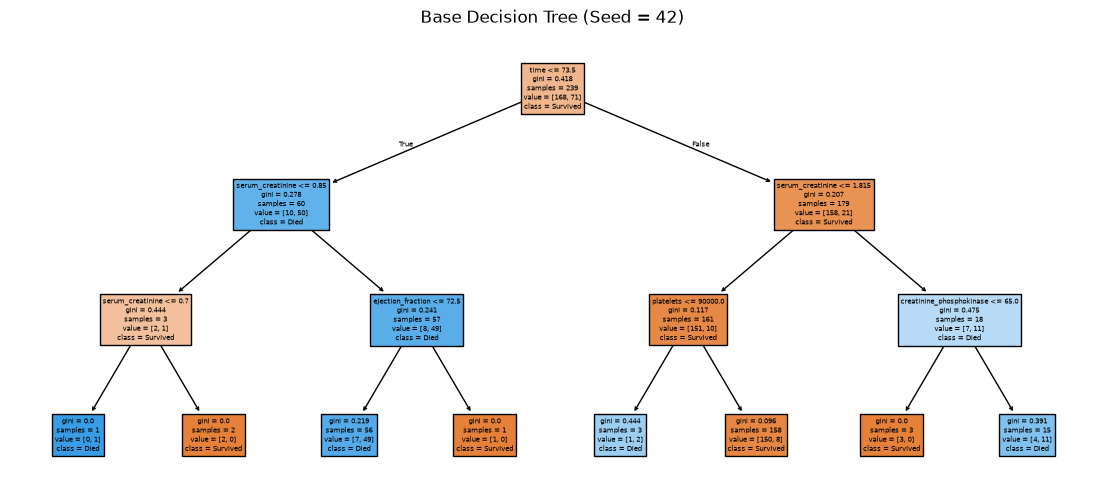


Base Logistic Regression Coefficients:
age                         0.6563
anaemia                    -0.0519
creatinine_phosphokinase    0.1132
diabetes                    0.1643
ejection_fraction          -0.8890
high_blood_pressure        -0.0611
platelets                  -0.1764
serum_creatinine            0.7279
serum_sodium               -0.2596
sex                        -0.3618
smoking                     0.0719
time                       -1.6385
dtype: float64


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# separate features (X) and target (y)
X = df_clean.drop('DEATH_EVENT', axis=1)
y = df_clean['DEATH_EVENT']

seed_base = 42      # saved for reproducibility
TREE_DEPTH = 3      # same depth for every seed so only the data changes

# One scaler fit on the features only (never the outcome), shared by every model,
# so logistic coefficients are on the same scale across seeds and directly comparable.
scaler = StandardScaler().fit(X)

def fit_models(seed):
    """Split with the given seed, fit a tree and a logistic regression on the training data."""
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed)
    tree = DecisionTreeClassifier(max_depth=TREE_DEPTH, random_state=seed).fit(X_tr, y_tr)
    log = LogisticRegression(max_iter=1000).fit(scaler.transform(X_tr), y_tr)
    return dict(seed=seed, X_train=X_tr, X_test=X_te, y_train=y_tr, y_test=y_te,
                tree=tree, log=log)

base = fit_models(seed_base)
tree_base, log_base = base['tree'], base['log']
X_train, X_test = base['X_train'], base['X_test']
y_train, y_test = base['y_train'], base['y_test']

# evaluate performance
tree_test_classes = tree_base.predict(X_test)
log_test_classes = log_base.predict(scaler.transform(X_test))

print(f"Decision Tree Train accuracy: {accuracy_score(y_train, tree_base.predict(X_train)):.4f}")
print(f"Logistic Regression Train accuracy: {accuracy_score(y_train, log_base.predict(scaler.transform(X_train))):.4f}")

print(f"\nDecision Tree Test Accuracy: {accuracy_score(y_test, tree_test_classes):.4f}")
print("Decision Tree Confusion Matrix:\n", confusion_matrix(y_test, tree_test_classes))

print(f"\nLogistic Regression Test Accuracy: {accuracy_score(y_test, log_test_classes):.4f}")
print("Logistic Regression Confusion Matrix:\n", confusion_matrix(y_test, log_test_classes))
print("\nBaseline accuracy:\n", y_test.value_counts(normalize=True))
print("Test set size:", len(y_test))

# set aside the predictions (predicted probability of death)
pred_tree_base = tree_base.predict_proba(X_test)[:, 1]
pred_log_base = log_base.predict_proba(scaler.transform(X_test))[:, 1]

# inspect the base tree and logistic coefficients
plt.figure(figsize=(14, 6))
plot_tree(tree_base, feature_names=X.columns, class_names=['Survived', 'Died'], filled=True)
plt.title(f"Base Decision Tree (Seed = {seed_base})")
plt.show()

print("\nBase Logistic Regression Coefficients:")
print(pd.Series(log_base.coef_[0], index=X.columns).round(4))

After splitting the data 80/20 using a seed of 42, we fit a decision tree and a logistic regression model on our training data. We used logistic regression rather than linear regression because our target variable, DEATH_EVENT, is binary (and a linear model could predict a result below 0 or above 1). On the test data, the logistic regression was more accurate than the decision tree, at 80% versus 68.3%. For this specific seed, the baseline of always predicting survival (DEATH_EVENT = 0) was 58.3%, so both models performed better than the baseline.

Looking at the confusion matrices, the decision tree correctly predicted death 13 out of 25 times and produced 7 false positives, predicting death for 7 patients who actually survived. In comparison, the logistic regression correctly predicted 14 out of 25 deaths and produced only 1 false positive. Overall, although both models identified death only about half the time, the logistic regression did a much better job of not falsely predicting death.

The decision tree had a much larger gap between training and test accuracy (91.6% vs. 68.3%), which suggests overfitting. The logistic regression was more consistent across the two sets.

A Caveat is that the test set has only 60 patients, so a single split's accuracy is noisy (the standard error of an accuracy near 80% on 60 patients is roughly 5 percentage points). The gap between the two models on this one seed should therefore not be over-interpreted. Question 3 shows that test accuracy for the same model type varies a lot across seeds.

# Question 3: Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients? Set aside the predictions these models make.

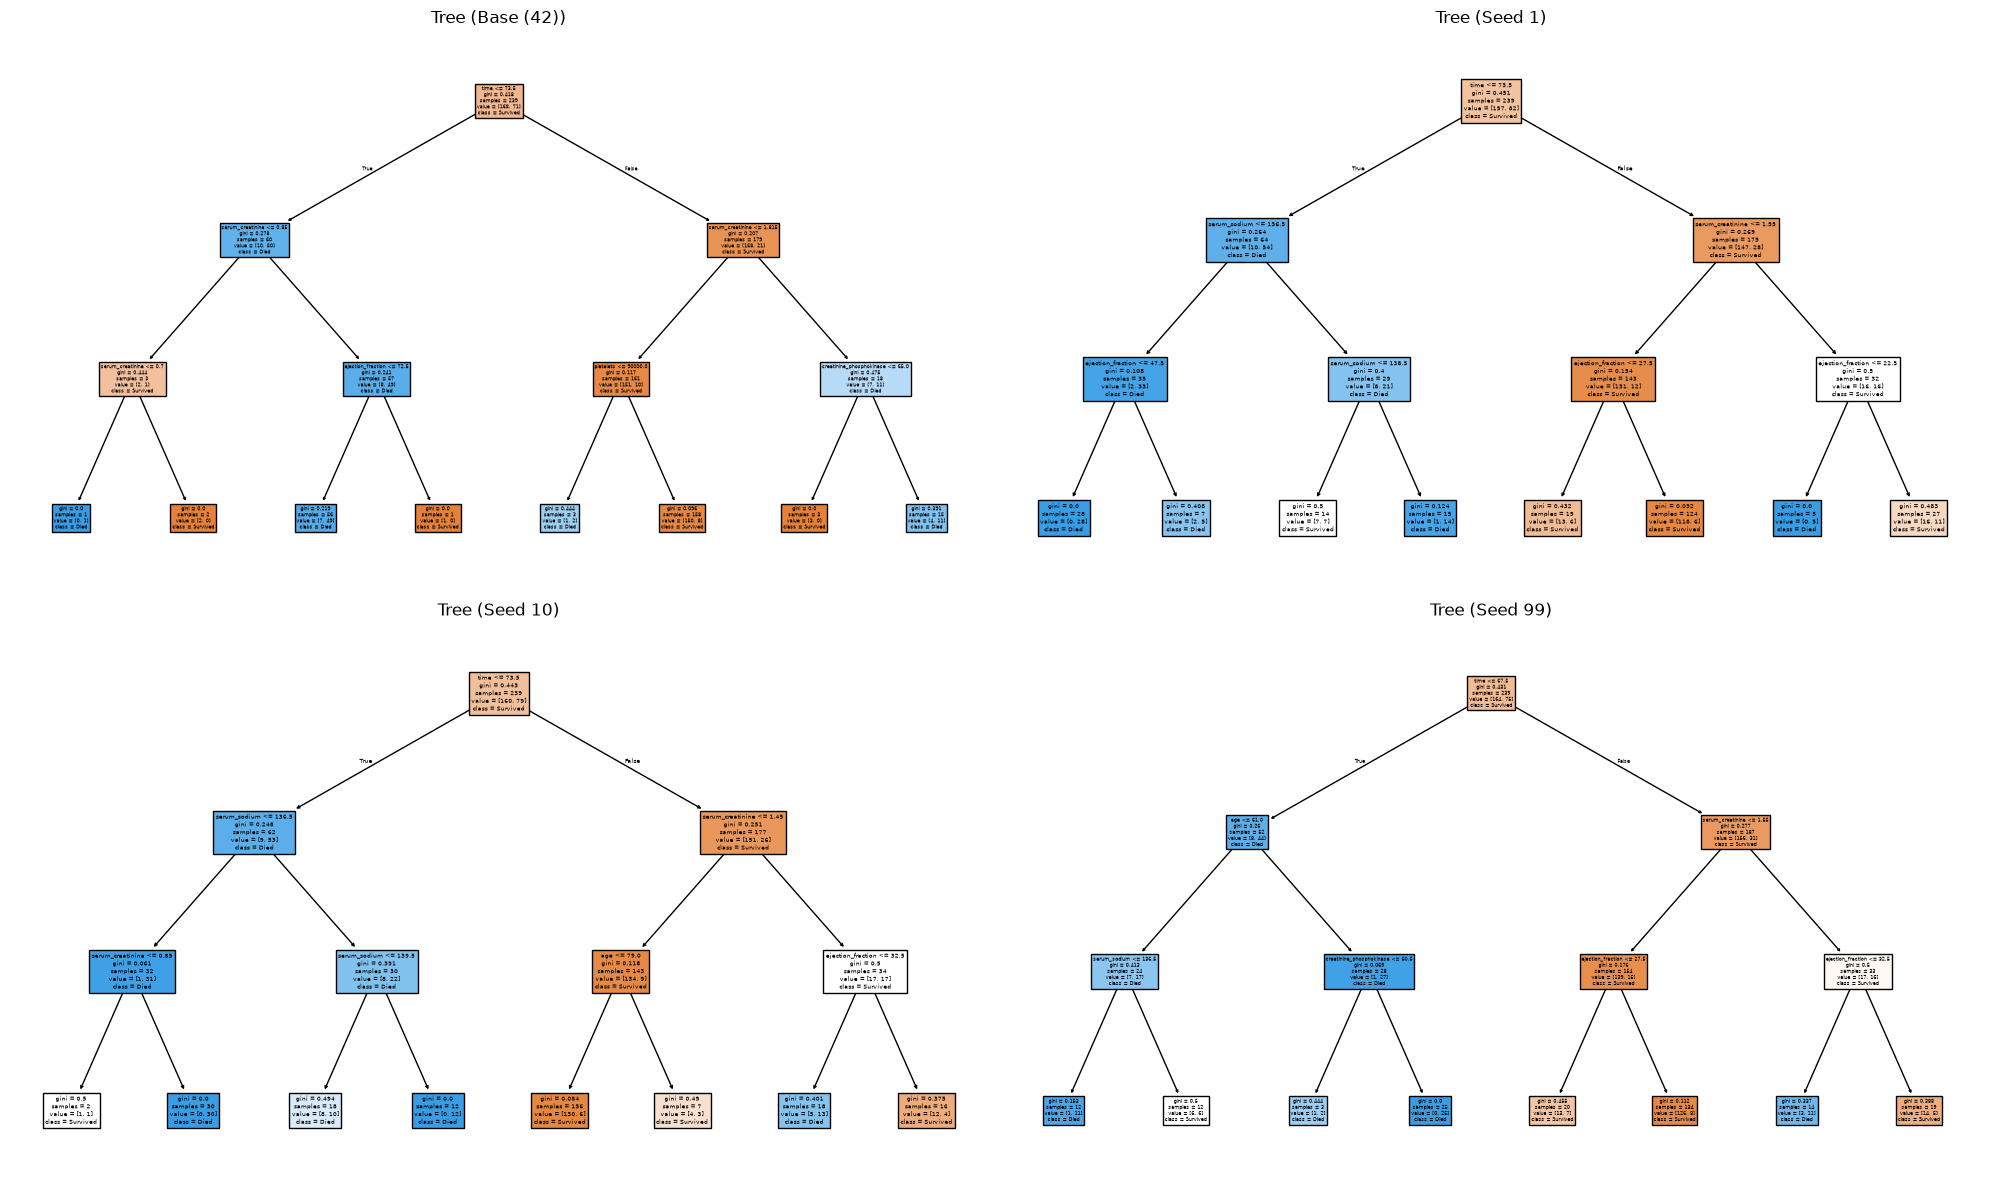

Logistic Regression Coefficients Across Seeds:
                          Base (42)  Seed 1  Seed 10  Seed 99
age                          0.6563  0.4223   0.5838   0.5669
anaemia                     -0.0519 -0.0288   0.1514  -0.0983
creatinine_phosphokinase     0.1132  0.2072   0.1928   0.1546
diabetes                     0.1643  0.1789   0.1628   0.0662
ejection_fraction           -0.8890 -0.7873  -0.9807  -0.8896
high_blood_pressure         -0.0611 -0.1231  -0.0713   0.0373
platelets                   -0.1764 -0.2516  -0.1780  -0.1902
serum_creatinine             0.7279  0.6984   1.1763   0.6788
serum_sodium                -0.2596 -0.2733  -0.2919  -0.2623
sex                         -0.3618 -0.1803  -0.1760  -0.2153
smoking                      0.0719 -0.0436  -0.0687   0.0673
time                        -1.6385 -1.4721  -1.6225  -1.3590

Coefficient range across seeds:
                             min     max  sign_flips
age                       0.4223  0.6563       False
anaemia 

In [16]:
seeds = [1, 10, 99]   # alternative seeds, saved for reproducibility
runs = {seed_base: base}
runs.update({s: fit_models(s) for s in seeds})
labels = {s: (f'Base ({s})' if s == seed_base else f'Seed {s}') for s in runs}

# Set aside predictions from every model on the SAME (base) test set
preds = {'Tree': {}, 'Logistic': {}}
for s, r in runs.items():
    preds['Tree'][s] = r['tree'].predict_proba(X_test)[:, 1]
    preds['Logistic'][s] = r['log'].predict_proba(scaler.transform(X_test))[:, 1]

# Compare the four trees side by side
fig, axes = plt.subplots(2, 2, figsize=(20, 12))
for ax, (s, r) in zip(axes.flatten(), runs.items()):
    plot_tree(r['tree'], feature_names=X.columns, class_names=['Survived', 'Died'],
              filled=True, ax=ax)
    ax.set_title(f"Tree ({labels[s]})")
plt.tight_layout()
plt.show()

# Compare logistic coefficients (all on the same standardized scale)
coef_table = pd.DataFrame({labels[s]: r['log'].coef_[0] for s, r in runs.items()},
                          index=X.columns)
print("Logistic Regression Coefficients Across Seeds:")
print(coef_table.round(4))

# Verification: range and sign flips for each coefficient
coef_summary = pd.DataFrame({
    'min': coef_table.min(axis=1),
    'max': coef_table.max(axis=1),
    'sign_flips': np.sign(coef_table).nunique(axis=1) > 1
})
print("\nCoefficient range across seeds:")
print(coef_summary.round(4))

# Test accuracy of each model on its own seed's test set
accuracy = pd.DataFrame({
    'Decision Tree': [accuracy_score(r['y_test'], r['tree'].predict(r['X_test']))
                      for r in runs.values()],
    'Logistic Regression': [accuracy_score(r['y_test'], r['log'].predict(scaler.transform(r['X_test'])))
                            for r in runs.values()]
}, index=[labels[s] for s in runs])
print("\nTest Accuracy Across Seeds:")
print(accuracy.round(4))

**Setup note.** Every tree uses `max_depth=3`, and every logistic model uses the same standardizing scaler (fit on the features only), so the only thing that changes across seeds is which patients land in the training set. The coefficient table above has the base seed (42) in the first column so each seed can be compared to it directly.

**How different are the decision trees?**

Across the different random train-test splits, the decision trees change quite a bit, especially below the very top split. All four trees start by splitting on time, though even that cutoff shifts slightly: it is time <= 73.5 for seeds 42, 1, and 10 and drops to time <= 67.5 for seed 99. Below that, the trees diverge. On the left side (time <= 73.5), the base tree splits on serum_creatinine and ejection_fraction, seeds 1 and 10 both switch to serum_sodium, and seed 99 switches to age. On the right side, the bottom splits bounce between platelets, creatinine_phosphokinase, ejection_fraction, and age depending on the seed. Because a decision tree builds its branches one greedy step at a time, a small change in the training data can change which split looks best, and that changes every branch underneath it. These differences also affect performance: test accuracy ranges from 68.3% to 86.7% across seeds. A shallow tree (depth 3) was used here, so if anything this understates the instability, since deeper trees have more splits that can change.

**How different are the linear model coefficients?**

The logistic regression coefficients are much more stable. The most influential features keep the same sign and similar magnitude in every split: time ranges from -1.36 to -1.64, ejection_fraction from -0.79 to -0.98, serum_creatinine from 0.68 to 1.18, age from 0.42 to 0.66, and serum_sodium from -0.26 to -0.29. Only small-magnitude coefficients (anaemia, high_blood_pressure, and smoking) change sign, as the sign_flips column shows. Unlike the tree, logistic regression uses all training samples to fit all coefficients at once, so a different sample shifts them only slightly. Test accuracy still varied across seeds (71.7% to 88.3%), a spread similar to the tree's, which reflects the small 60-patient test sets as much as the models.

# Question 4: Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. But are they? Instead of focusing on the tree or model coefficients, do three things:

Seed 1: 85% of the base test set was in this model's training data
Seed 10: 80% of the base test set was in this model's training data
Seed 99: 85% of the base test set was in this model's training data


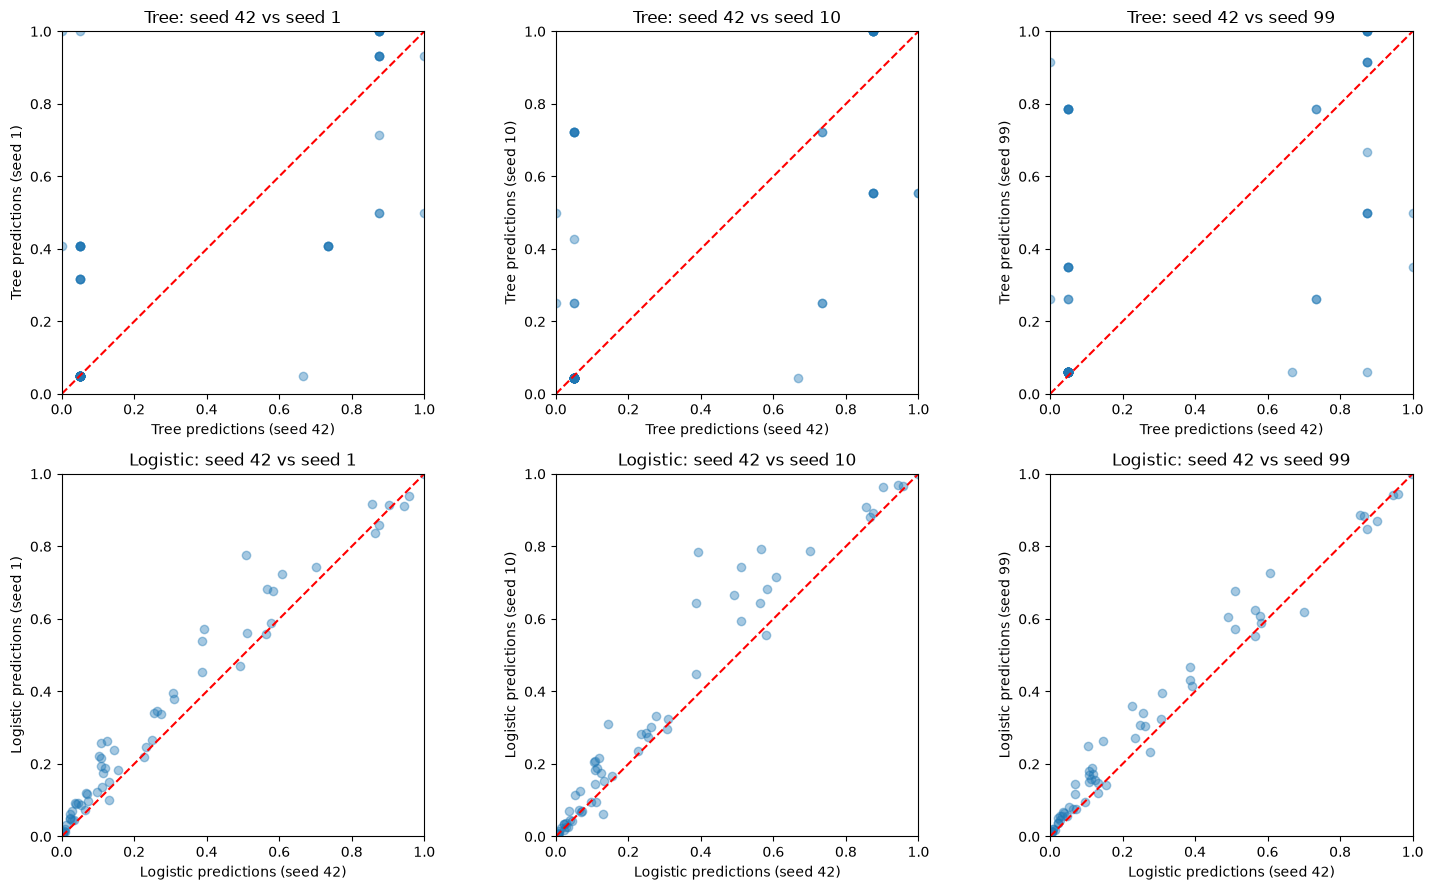

      Model  Seed  Correlation  Intercept  Slope    R^2
0      Tree     1        0.733      0.147  0.697  0.538
1      Tree    10        0.730      0.128  0.700  0.533
2      Tree    99        0.589      0.189  0.543  0.347
3  Logistic     1        0.982      0.052  0.986  0.965
4  Logistic    10        0.973      0.033  1.061  0.946
5  Logistic    99        0.988      0.040  0.978  0.976


In [17]:
from scipy import stats

# Limitation check: how many base-test patients were in each alternative model's TRAINING set?
for s in seeds:
    overlap = X_test.index.isin(runs[s]['X_train'].index).mean()
    print(f"Seed {s}: {overlap:.0%} of the base test set was in this model's training data")

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
rows = []
for i, k in enumerate(['Tree', 'Logistic']):
    for j, s in enumerate(seeds):
        x_, y_ = preds[k][seed_base], preds[k][s]

        ax = axes[i, j]
        ax.scatter(x_, y_, alpha=0.4)      # alpha shows stacked points (trees give few distinct values)
        ax.plot([0, 1], [0, 1], 'r--')     # y = x reference line
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal')
        ax.set_xlabel(f'{k} predictions (seed {seed_base})')
        ax.set_ylabel(f'{k} predictions (seed {s})')
        ax.set_title(f'{k}: seed {seed_base} vs seed {s}')

        res = stats.linregress(x_, y_)
        rows.append({'Model': k, 'Seed': s, 'Correlation': res.rvalue,
                     'Intercept': res.intercept, 'Slope': res.slope, 'R^2': res.rvalue ** 2})

plt.tight_layout()
plt.show()

q4_table = pd.DataFrame(rows)
print(q4_table.round(3))

As discussed in Q3, the logistic regression coefficients vary somewhat across seeds. For example, serum_creatinine ranges from 0.68 to 1.18 and a few small coefficients flip sign. Even so, the predictions these models make on the same test set are very similar, so the coefficient changes are not as substantial as they first appear.

**Limitation:** All models are scored on the seed-42 test set, but that set is not held out from the other seeds: many of its patients were in the *training* data of the alternative models (the overlap check above gives the exact percentages). This can make the alternative models look more similar to the base model than truly independent models would. We still use this comparison because it puts every model's predictions on the same patients, but the similarity numbers should be read with this in mind.

**a. Scatterplots:** For logistic regression, the points sit close to the red y = x line in all three plots, so the alternative models give very similar predictions to the seed-42 model. The points sit slightly above the line in the middle range, most visibly for seed 10. For the trees, the points are scattered, with stacked points at a few distinct values because a depth-3 tree can output at most 8 distinct probabilities. Many points are far from the line (for example, patients the seed-42 tree scores near 0.05 receive scores as high as 0.7 to 1.0 from an alternative tree). The logistic predictions look reasonably similar; the tree predictions do not.

**b. Correlations:** Logistic predictions are very highly correlated with the seed-42 model: 0.982 (seed 1), 0.973 (seed 10), and 0.988 (seed 99), so seed 99 is the *most* correlated for logistic regression. Tree predictions are only moderately correlated: 0.733 (seed 1), 0.730 (seed 10), and 0.589 (seed 99), so seed 99 is the *least* correlated for trees.

**c. Regression of alternative predictions on seed-42 predictions:** Logistic regression: intercepts 0.033 to 0.052 (close to 0), slopes 0.978 to 1.061 (close to 1), and R² 0.946 to 0.976 (close to 1). The alternative models essentially reproduce the seed-42 predictions. Trees: intercepts 0.128 to 0.189 (not close to 0), slopes 0.543 to 0.700 (well below 1), and R² 0.347 to 0.538 (low). The alternative trees do not reproduce the seed-42 predictions, and their predictions are compressed toward the middle.

# Question 5: Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?

Linear (logistic) models appear to have similar coefficients and predictions across the train and test splits. The coefficients vary slightly across seeds, but the larger-magnitude coefficients, which have the most impact on the prediction, such as time (-1.36 to -1.64), ejection_fraction (-0.79 to -0.98), and serum_creatinine (0.68 to 1.18), keep the same sign across all seeds. Only small-magnitude coefficients such as anaemia, high_blood_pressure, and smoking flip signs. When each seed's model predicted on the same seed-42 test set, the correlations with the seed-42 model ranged from 0.97 to 0.99, the slopes were close to one (0.98 to 1.06), the intercepts were close to zero (0.03 to 0.05), and the R² values were close to one (0.95 to 0.98). This shows the predictions do not change much across seeds.

Decision trees are much less similar across splits. Although all four trees made their first split on time, the cutoffs differed (73.5 versus 67.5) and the splits below changed with the seed. For example, serum_sodium, age, and platelets are decision nodes in some trees but not in others. The trees also predicted much more accurately on their training data than on their test data, as discussed in Q2. Predictions are not very similar because each tree node picks the best split at that step without considering later splits, so small differences in the training sample can change the structure of the tree. Our data supports this: correlations with the seed-42 tree ranged from 0.59 to 0.73, slopes from 0.54 to 0.70, and R² from 0.35 to 0.54.

# Question 6: True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

**It depends on the model: true for logistic regression, false for decision trees on this dataset.**

For logistic regression, the coefficients look different across seeds (serum_creatinine ranges from 0.68 to 1.18, and small coefficients such as anaemia and smoking even flip sign), yet the predictions are nearly identical. Compared with the seed-42 model on the same test set, the correlations are 0.97-0.99, the slopes are 0.98-1.06, the intercepts are 0.03-0.05, and R² is 0.95-0.98. So models that look different generate very similar predictions.

For decision trees, the models look different (different splits below the first time split) and the predictions are also different: correlations are only 0.59-0.73, slopes 0.54-0.70, and R² 0.35-0.54. Here the difference in appearance does reflect a real difference in predictions.

The reason is how each model is fit. A tree picks each split greedily, so a small change in the training data can change the structure and the predictions with it. Logistic regression fits all coefficients jointly, so a different training sample shifts them only slightly, and correlated features can trade off against each other without changing the overall predictions. The statement is therefore only conditionally true: it holds for the logistic model but not for the tree.

### *Reflection on AI assistance
In your own words without generative AI.

The biggest AI improvement wasn't simply correcting mistakes, but making our analysis clearer and more consistent. In Phase 1, we were able to complete the analysis ourselves and draw conclusions about the stability of decision trees compared with logistic regression. However, Phase 2 helped us identify some wording errors, clarify our explanations, and strengthen how we interpreted the results. In particular, we improved our explanation of how different train-test splits affect the models and made our conclusions more precise.

The use of AI also helped us recognize limitations that we had not fully addressed in Phase 1. We added a caveat about the small test set, clarified that alternative models were evaluated on a test set that some had already seen during training, and included more specific numerical evidence to support our conclusions. Additionally, we streamlined the code by using a function and loop rather than repeating code for each seed. We did not accept every suggestion, since some changes were unnecessary given the assignment requirements. Another limitation we noticed from the use of AI is the need to double check all results manually. We checked the proposed revisions against our code, outputs, and original instructions before incorporating them. Overall, AI was most useful as a second reviewer that helped us catch errors and improve clarity, rather than replacing our own analysis.